Original Dataset:


,Duration,Date,Pulse,Maxpulse,Calories
0,60,'2020/12/01',110,130,409.1
1,60,'2020/12/02',117,145,479.0
2,60,'2020/12/03',103,135,340.0
3,45,'2020/12/04',109,175,282.4
4,45,'2020/12/05',117,148,406.0


Original Shape: (32, 5)

Missing Values Before Cleaning:
Duration    0
Date        1
Pulse       0
Maxpulse    0
Calories    2
dtype: int64

Duplicate Rows: 1

Missing Values After Cleaning:
Duration    0
Date        0
Pulse       0
Maxpulse    0
Calories    0
dtype: int64

Dataset Shape After Cleaning: (31, 5)

Rows Where Duration >= 45:


,Duration,Date,Pulse,Maxpulse,Calories
0,60,2020-12-01,110,130,409.1
1,60,2020-12-02,117,145,479.0
2,60,2020-12-03,103,135,340.0
3,45,2020-12-04,109,175,282.4
4,45,2020-12-05,117,148,406.0
5,60,2020-12-06,102,127,300.0
6,60,2020-12-07,110,136,374.0
7,450,2020-12-08,104,134,253.3
9,60,2020-12-10,98,124,269.0
10,60,2020-12-11,103,147,329.3



Dataset With New Columns:


,Duration,Date,Pulse,Maxpulse,Calories,Calories_Per_Minute,Pulse_Category
0,60,2020-12-01,110,130,409.1,6.82,High
1,60,2020-12-02,117,145,479.0,7.98,High
2,60,2020-12-03,103,135,340.0,5.67,High
3,45,2020-12-04,109,175,282.4,6.28,High
4,45,2020-12-05,117,148,406.0,9.02,High
5,60,2020-12-06,102,127,300.0,5.00,High
6,60,2020-12-07,110,136,374.0,6.23,High
7,450,2020-12-08,104,134,253.3,0.56,High
8,30,2020-12-09,109,133,195.1,6.50,High
9,60,2020-12-10,98,124,269.0,4.48,Normal



Summary Statistics:


,Duration,Date,Pulse,Maxpulse,Calories,Calories_Per_Minute
count,31.000000,31,31.000000,31.000000,31.000000,31.000000
mean,68.709677,2020-12-15 22:27:05.806451,103.612903,128.774194,306.119355,5.404839
min,30.000000,2020-12-01 00:00:00,90.000000,101.000000,195.100000,0.560000
25%,60.000000,2020-12-08 12:00:00,100.000000,120.000000,252.000000,4.625000
50%,60.000000,2020-12-16 00:00:00,103.000000,128.000000,300.000000,5.470000
75%,60.000000,2020-12-23 12:00:00,107.000000,132.500000,342.650000,6.275000
max,450.000000,2020-12-31 00:00:00,130.000000,175.000000,479.000000,9.020000
std,71.180144,NaN,7.935899,13.119222,64.136367,1.476125


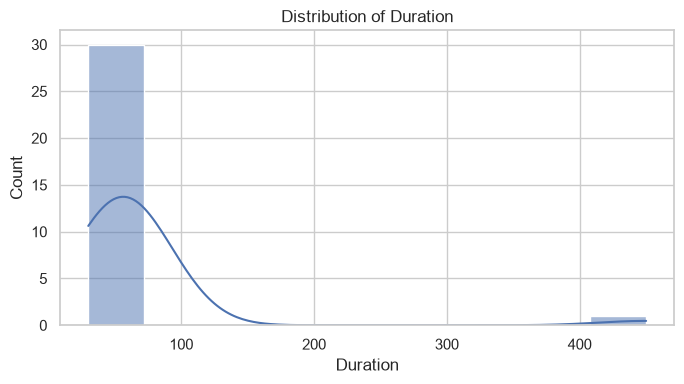

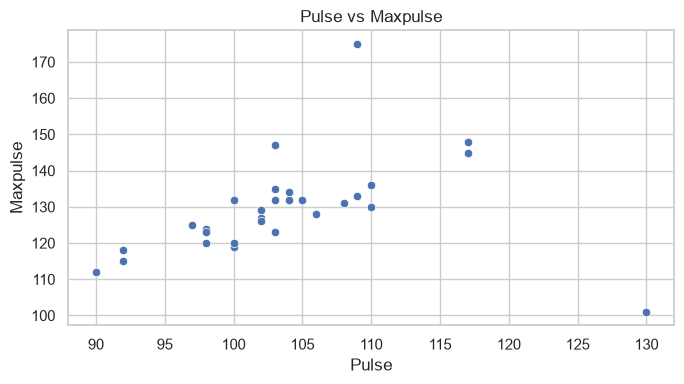

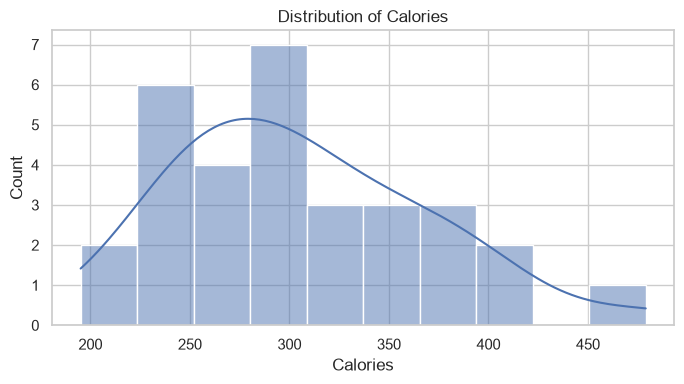


Final Cleaned Dataset:


,Duration,Date,Pulse,Maxpulse,Calories,Calories_Per_Minute,Pulse_Category
0,60,2020-12-01,110,130,409.1,6.82,High
1,60,2020-12-02,117,145,479.0,7.98,High
2,60,2020-12-03,103,135,340.0,5.67,High
3,45,2020-12-04,109,175,282.4,6.28,High
4,45,2020-12-05,117,148,406.0,9.02,High
5,60,2020-12-06,102,127,300.0,5.00,High
6,60,2020-12-07,110,136,374.0,6.23,High
7,450,2020-12-08,104,134,253.3,0.56,High
8,30,2020-12-09,109,133,195.1,6.50,High
9,60,2020-12-10,98,124,269.0,4.48,Normal


Final Dataset Shape: (31, 7)

Remaining Missing Values:
Duration               0
Date                   0
Pulse                  0
Maxpulse               0
Calories               0
Calories_Per_Minute    0
Pulse_Category         0
dtype: int64

Cleaned dataset saved as cleaned_data.csv


In [1]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("data.csv")

df.columns = df.columns.str.strip()

print("Original Dataset:")
display(df.head())
print("Original Shape:", df.shape)

print("\nMissing Values Before Cleaning:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

df.drop_duplicates(inplace=True)

for col in ["Duration", "Pulse", "Maxpulse", "Calories"]:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

if "Date" in df.columns:
    df["Date"] = (
        df["Date"].astype("string")
        .str.strip()
        .str.replace("'", "", regex=False)
    )
    df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

for col in ["Duration", "Pulse", "Maxpulse", "Calories"]:
    if col in df.columns and df[col].notna().any():
        df[col] = df[col].fillna(df[col].median())

if "Date" in df.columns:
    df["Date"] = df["Date"].ffill()

print("\nMissing Values After Cleaning:")
print(df.isnull().sum())

print("\nDataset Shape After Cleaning:", df.shape)

if "Duration" in df.columns:
    filtered_df = df[df["Duration"] >= 45]
    print("\nRows Where Duration >= 45:")
    display(filtered_df)

if "Duration" in df.columns and "Calories" in df.columns:
    df["Calories_Per_Minute"] = (
        df["Calories"] / df["Duration"].replace(0, float("nan"))
    ).round(2)

if "Pulse" in df.columns:
    df["Pulse_Category"] = df["Pulse"].apply(
        lambda x: "High" if x > 100 else "Normal"
    )

print("\nDataset With New Columns:")
display(df.head(10))

print("\nSummary Statistics:")
display(df.describe())

sns.set_theme(style="whitegrid")

if "Duration" in df.columns:
    plt.figure(figsize=(7, 4))
    sns.histplot(data=df, x="Duration", bins=10, kde=True)
    plt.title("Distribution of Duration")
    plt.tight_layout()
    plt.show()

if "Pulse" in df.columns and "Maxpulse" in df.columns:
    plt.figure(figsize=(7, 4))
    sns.scatterplot(data=df, x="Pulse", y="Maxpulse")
    plt.title("Pulse vs Maxpulse")
    plt.tight_layout()
    plt.show()

if "Calories" in df.columns:
    plt.figure(figsize=(7, 4))
    sns.histplot(data=df, x="Calories", bins=10, kde=True)
    plt.title("Distribution of Calories")
    plt.tight_layout()
    plt.show()

print("\nFinal Cleaned Dataset:")
display(df)

print("Final Dataset Shape:", df.shape)

print("\nRemaining Missing Values:")
print(df.isnull().sum())

df.to_csv("cleaned_data.csv", index=False)

print("\nCleaned dataset saved as cleaned_data.csv")


In [5]:
original_df = pd.read_csv("data.csv")

print(original_df[original_df["Duration"] > 120])

   Duration          Date  Pulse  Maxpulse  Calories
7       450  '2020/12/08'    104       134     253.3


In [6]:

original_df = pd.read_csv("data.csv")

print(original_df[original_df["Date"].isnull()])


    Duration Date  Pulse  Maxpulse  Calories
22        45  NaN    100       119     282.0


In [7]:

print(original_df.loc[10:15, ["Duration", "Date"]])


    Duration          Date
10        60  '2020/12/11'
11        60  '2020/12/12'
12        60  '2020/12/12'
13        60  '2020/12/13'
14        60  '2020/12/14'
15        60  '2020/12/15'
